# Corrected TMS information and workspace analyses

Current results, 26 November 2026. Aachen uses the corrected anatomical branch; historical Aachen treatment effects are superseded. SUDMEX inputs are unchanged. All tests are exploratory and retain their full stated family. No preprocessing or psychedelic calculation runs in this notebook.

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Image
ROOT=Path(r'D:\projects\TMS_GWT')
RUN=ROOT/'output/corrected_tms_analysis/20261126T112054_284547Z'
TARGET=ROOT/'output/corrected_aachen_target_flow/20261126T113156_656159Z'
assert json.loads((RUN/'status.json').read_text())['normalized']=='complete'
pd.set_option('display.max_rows',100)
read=lambda name: pd.read_csv(RUN/name)

## Whole brain and fixed workspace
Five information measures per scope; the complete forty-endpoint correction is also visible. Confidence intervals are marginal, not simultaneous. Normalized information values are CDF units; multiply by 100 for percentile points.

In [2]:
for branch in ['raw','normalized']:
    print(branch)
    d=read(branch+'_aachen_all40.csv')
    display(d[d.metric.str.startswith(('whole_brain__','within_workspace__'))][['metric','estimate','ci_low','ci_high','p','p_maxT_family','p_maxT_whole_and_workspace10','p_maxT_all']])

raw


,metric,estimate,ci_low,ci_high,p,p_maxT_family,p_maxT_whole_and_workspace10,p_maxT_all
0,whole_brain__synergy,-0.011783,-0.023340,-0.000226,0.046235,0.143188,0.194458,0.549133
1,whole_brain__redundancy,0.000047,-0.001672,0.001765,0.954259,0.999939,1.000000,1.000000
2,whole_brain__synergy_total,-0.004803,-0.009399,-0.000207,0.041726,0.127319,0.174683,0.508728
3,whole_brain__phi,0.001349,-0.001525,0.004224,0.331194,0.744080,0.826965,0.998413
4,whole_brain__phi_r,0.001396,-0.001378,0.004170,0.298745,0.706482,0.789856,0.996521
5,within_workspace__synergy,-0.008180,-0.018477,0.002116,0.110471,0.323853,0.424377,0.846436
6,within_workspace__redundancy,0.000335,-0.000819,0.001489,0.543835,0.928650,0.967590,1.000000
7,within_workspace__synergy_total,-0.002232,-0.006326,0.001861,0.261724,0.648499,0.741882,0.988708
8,within_workspace__phi,0.001935,-0.000484,0.004353,0.108227,0.317505,0.417664,0.843994
9,within_workspace__phi_r,0.002269,-0.000272,0.004811,0.076086,0.223938,0.311829,0.737488


normalized


,metric,estimate,ci_low,ci_high,p,p_maxT_family,p_maxT_whole_and_workspace10,p_maxT_all
0,whole_brain__synergy,-0.002660,-0.010775,0.005455,0.493581,0.869019,0.934509,1.000000
1,whole_brain__redundancy,0.002166,-0.010739,0.015071,0.724210,0.978394,0.994324,1.000000
2,whole_brain__synergy_total,0.004099,-0.013190,0.021389,0.619010,0.941162,0.977966,1.000000
3,whole_brain__phi,0.006824,-0.005429,0.019077,0.252154,0.602722,0.716858,0.991455
4,whole_brain__phi_r,0.006226,-0.003991,0.016443,0.212289,0.537903,0.652039,0.977295
5,within_workspace__synergy,-0.003683,-0.010581,0.003214,0.271280,0.671753,0.745239,0.994019
6,within_workspace__redundancy,0.004478,-0.004908,0.013864,0.323533,0.742798,0.809570,0.998352
7,within_workspace__synergy_total,0.004617,-0.011371,0.020605,0.545632,0.917969,0.956116,1.000000
8,within_workspace__phi,0.007901,-0.002549,0.018352,0.127181,0.371765,0.457153,0.890564
9,within_workspace__phi_r,0.008329,-0.001134,0.017791,0.079957,0.236877,0.311829,0.749023


## Four expectations motivated by Yousefi
FPN and DAN gateways, redundancy participation, synergy participation. Directional expectation: increase; tests remain two-sided. A coefficient describes network distribution, not the amount of redundant information.

In [3]:
for branch in ['raw','normalized']:
    display(read('gwt_expectations_'+branch+'.csv')[['dataset','metric','n','estimate','ci_low','ci_high','p','p_holm4','p_maxT4']])

,dataset,metric,n,estimate,ci_low,ci_high,p,p_holm4,p_maxT4
0,aachen_itbs,gateways_FPN,15,-0.133333,-1.491698,1.225032,0.836290,1.000000,0.999817
1,aachen_itbs,gateways_DAN,15,-0.400000,-0.893101,0.093101,0.103814,0.311442,0.388794
2,aachen_itbs,mean_redundancy_pc,15,0.004661,0.000538,0.008785,0.029456,0.117824,0.114136
3,aachen_itbs,mean_synergy_pc,15,0.000069,-0.000209,0.000348,0.601593,1.000000,0.972107
4,sudmex_tms,gateways_FPN,40,1.085125,-2.130075,4.300326,0.498056,1.000000,NaN
5,sudmex_tms,gateways_DAN,40,0.129547,-0.751890,1.010985,0.767360,1.000000,NaN
6,sudmex_tms,mean_redundancy_pc,40,-0.000295,-0.010557,0.009966,0.953762,1.000000,NaN
7,sudmex_tms,mean_synergy_pc,40,0.000008,-0.000334,0.000350,0.964416,1.000000,NaN


,dataset,metric,n,estimate,ci_low,ci_high,p,p_holm4,p_maxT4
0,aachen_itbs,gateways_FPN,15,-0.366667,-1.870447,1.137114,0.609178,1.00000,0.982361
1,aachen_itbs,gateways_DAN,15,-0.466667,-0.904052,-0.029281,0.038182,0.15273,0.162109
2,aachen_itbs,mean_redundancy_pc,15,0.001194,-0.000002,0.002390,0.050377,0.15273,0.192444
3,aachen_itbs,mean_synergy_pc,15,-0.000005,-0.000191,0.000181,0.957800,1.00000,1.000000
4,sudmex_tms,gateways_FPN,40,1.092768,-1.984888,4.170424,0.476110,1.00000,NaN
5,sudmex_tms,gateways_DAN,40,0.400113,-0.598836,1.399061,0.421947,1.00000,NaN
6,sudmex_tms,mean_redundancy_pc,40,-0.000120,-0.002448,0.002209,0.917477,1.00000,NaN
7,sudmex_tms,mean_synergy_pc,40,-0.000124,-0.000350,0.000103,0.274598,1.00000,NaN


## All information and role endpoints
The full forty-outcome inventory prevents a selected nominal result from standing in for the entire analysis.

In [4]:
display(read('raw_aachen_all40.csv')[['metric','family','estimate','p','p_maxT_family','p_maxT_all']])

,metric,family,estimate,p,p_maxT_family,p_maxT_all
0,whole_brain__synergy,whole_brain,-0.011783,0.046235,0.143188,0.549133
1,whole_brain__redundancy,whole_brain,0.000047,0.954259,0.999939,1.000000
2,whole_brain__synergy_total,whole_brain,-0.004803,0.041726,0.127319,0.508728
3,whole_brain__phi,whole_brain,0.001349,0.331194,0.744080,0.998413
4,whole_brain__phi_r,whole_brain,0.001396,0.298745,0.706482,0.996521
5,within_workspace__synergy,within_workspace,-0.008180,0.110471,0.323853,0.846436
6,within_workspace__redundancy,within_workspace,0.000335,0.543835,0.928650,1.000000
7,within_workspace__synergy_total,within_workspace,-0.002232,0.261724,0.648499,0.988708
8,within_workspace__phi,within_workspace,0.001935,0.108227,0.317505,0.843994
9,within_workspace__phi_r,within_workspace,0.002269,0.076086,0.223938,0.737488


## Spatial scope and robustness

In [5]:
display(read('aachen_spatial_interactions.csv'))
display(read('aachen_all_spatial_motion.csv')[['branch','metric','estimate','ci_low','ci_high','p_holm_scope5','p_holm20']])
display(read('aachen_intensity_results.csv')[['branch','metric','contrast','estimate','ci_low','ci_high','p_holm_family']])

,branch,metric,contrast,n,estimate,ci_low,ci_high,t,df,p,effect_size,effect_size_type,status,p_sign_flip,p_maxT_5,p_holm5
0,raw,synergy,outside_minus_within_workspace,15,-0.005794,-0.015523,0.003935,-1.277270,14,0.222284,-0.311801,Hedges_g_z,ok,0.230164,0.621765,0.666851
1,raw,redundancy,outside_minus_within_workspace,15,-0.001033,-0.003747,0.001680,-0.816966,14,0.427632,-0.199434,Hedges_g_z,ok,0.426941,0.875366,0.855264
2,raw,synergy_total,outside_minus_within_workspace,15,-0.004707,-0.008889,-0.000526,-2.414681,14,0.030012,-0.589461,Hedges_g_z,ok,0.032349,0.120300,0.150062
3,raw,phi,outside_minus_within_workspace,15,-0.000771,-0.003290,0.001747,-0.656903,14,0.521896,-0.160360,Hedges_g_z,ok,0.526062,0.934937,0.855264
4,raw,phi_r,outside_minus_within_workspace,15,-0.001805,-0.004086,0.000477,-1.696419,14,0.111918,-0.414122,Hedges_g_z,ok,0.111755,0.376038,0.447674
5,normalized,synergy,outside_minus_within_workspace,15,0.003686,-0.008169,0.015541,0.666884,14,0.515688,0.162797,Hedges_g_z,ok,0.535156,0.902283,1.000000
6,normalized,redundancy,outside_minus_within_workspace,15,-0.007095,-0.023378,0.009189,-0.934448,14,0.365911,-0.228113,Hedges_g_z,ok,0.364990,0.766602,1.000000
7,normalized,synergy_total,outside_minus_within_workspace,15,0.001191,-0.011780,0.014162,0.196975,14,0.846678,0.048085,Hedges_g_z,ok,0.845520,0.998779,1.000000
8,normalized,phi,outside_minus_within_workspace,15,-0.000926,-0.009947,0.008094,-0.220265,14,0.828844,-0.053770,Hedges_g_z,ok,0.830078,0.998169,1.000000
9,normalized,phi_r,outside_minus_within_workspace,15,-0.004357,-0.010981,0.002267,-1.410846,14,0.180124,-0.344409,Hedges_g_z,ok,0.180054,0.482605,0.900618


,branch,metric,estimate,ci_low,ci_high,p_holm_scope5,p_holm20
0,raw,whole_brain__synergy,-0.012509,-0.024666,-0.000352,0.178316,0.713264
1,raw,whole_brain__redundancy,0.000101,-0.002477,0.002680,1.000000,1.000000
2,raw,whole_brain__synergy_total,-0.005139,-0.009622,-0.000657,0.138888,0.499996
3,raw,whole_brain__phi,0.001277,-0.001803,0.004357,1.000000,1.000000
4,raw,whole_brain__phi_r,0.001378,-0.002284,0.005040,1.000000,1.000000
5,raw,within_workspace__synergy,-0.008461,-0.019185,0.002263,0.560293,1.000000
6,raw,within_workspace__redundancy,0.000350,-0.001361,0.002060,0.665969,1.000000
7,raw,within_workspace__synergy_total,-0.002423,-0.006676,0.001829,0.560616,1.000000
8,raw,within_workspace__phi,0.001852,-0.000694,0.004397,0.560616,1.000000
9,raw,within_workspace__phi_r,0.002201,-0.000873,0.005275,0.560616,1.000000


,branch,metric,contrast,estimate,ci_low,ci_high,p_holm_family
0,raw,whole_brain__synergy,90_change,-0.009330,-0.027535,0.008876,1.000000
1,raw,whole_brain__synergy,120_change,-0.014237,-0.029431,0.000958,0.962376
2,raw,whole_brain__synergy,120_minus_90,-0.004907,-0.029204,0.019390,1.000000
3,raw,whole_brain__synergy,120_minus_90_order_baseline_motion,-0.001640,-0.016578,0.013298,1.000000
4,raw,whole_brain__redundancy,90_change,-0.000651,-0.002682,0.001379,1.000000
5,raw,whole_brain__redundancy,120_change,0.000745,-0.002074,0.003564,1.000000
6,raw,whole_brain__redundancy,120_minus_90,0.001396,-0.002114,0.004907,1.000000
7,raw,whole_brain__redundancy,120_minus_90_order_baseline_motion,0.000138,-0.002957,0.003233,1.000000
8,raw,whole_brain__synergy_total,90_change,-0.004749,-0.012729,0.003230,1.000000
9,raw,whole_brain__synergy_total,120_change,-0.004856,-0.010889,0.001176,1.000000


## Signal representation and haemodynamics
Method interactions and HRF associations are diagnostics on the same signals; they do not identify a stimulation effect.

In [6]:
display(read('sensitivities/estimator_sensitivity_results.csv'))
display(read('sensitivities/method_interactions.csv'))
display(read('sensitivities/hrf_phi_associations.csv'))

,metric,family,n,estimate,ci_low,ci_high,t,df,p,effect_size,effect_size_type,status,p_sign_flip,p_maxT_family,p_holm_family
0,deconvolved::whole_brain__phi,estimator_variants12,15,0.001349,-0.001525,0.004224,1.006631,14,0.331194,0.245734,Hedges_g_z,ok,0.350037,0.658569,1.0
1,deconvolved::within_workspace__phi,estimator_variants12,15,0.001935,-0.000484,0.004353,1.715840,14,0.108227,0.418863,Hedges_g_z,ok,0.092651,0.264038,1.0
2,deconvolved::outside_workspace__phi,estimator_variants12,15,0.001163,-0.003326,0.005652,0.555872,14,0.587073,0.135697,Hedges_g_z,ok,0.606445,0.928650,1.0
3,deconvolved::difference__phi,estimator_variants12,15,-0.000771,-0.003290,0.001747,-0.656903,14,0.521896,-0.160360,Hedges_g_z,ok,0.526062,0.878845,1.0
4,equal294::whole_brain__phi,estimator_variants12,15,0.001415,-0.001457,0.004287,1.056959,14,0.308429,0.258020,Hedges_g_z,ok,0.322937,0.625000,1.0
5,equal294::within_workspace__phi,estimator_variants12,15,0.002005,-0.000393,0.004404,1.792934,14,0.094609,0.437683,Hedges_g_z,ok,0.079529,0.235962,1.0
6,equal294::outside_workspace__phi,estimator_variants12,15,0.001264,-0.003236,0.005765,0.602635,14,0.556388,0.147113,Hedges_g_z,ok,0.571594,0.907654,1.0
7,equal294::difference__phi,estimator_variants12,15,-0.000741,-0.003286,0.001804,-0.624171,14,0.542553,-0.152370,Hedges_g_z,ok,0.547241,0.898376,1.0
8,no_deconvolution::whole_brain__phi,estimator_variants12,15,-0.000196,-0.004159,0.003766,-0.106358,14,0.916807,-0.025964,Hedges_g_z,ok,0.916931,0.999939,1.0
9,no_deconvolution::within_workspace__phi,estimator_variants12,15,-0.000076,-0.002792,0.002640,-0.059960,14,0.953035,-0.014637,Hedges_g_z,ok,0.958679,1.000000,1.0


,metric,family,n,estimate,ci_low,ci_high,t,df,p,effect_size,effect_size_type,status,p_sign_flip,p_maxT_family,p_holm_family
0,whole_brain__phi,deconvolution_interactions8,15,0.001546,0.000104,0.002987,2.300026,14,0.037348,0.561472,Hedges_g_z,ok,0.039612,0.162170,0.261439
1,whole_brain__phi_r,deconvolution_interactions8,15,0.001036,-0.000747,0.002819,1.245839,14,0.233270,0.304128,Hedges_g_z,ok,0.234375,0.682617,1.000000
2,within_workspace__phi,deconvolution_interactions8,15,0.002011,0.000984,0.003038,4.199193,14,0.000892,1.025087,Hedges_g_z,ok,0.000183,0.002502,0.007136
3,within_workspace__phi_r,deconvolution_interactions8,15,0.001039,-0.000175,0.002253,1.835706,14,0.087729,0.448124,Hedges_g_z,ok,0.088257,0.338623,0.526375
4,outside_workspace__phi,deconvolution_interactions8,15,0.000779,-0.002130,0.003689,0.574545,14,0.574716,0.140255,Hedges_g_z,ok,0.573303,0.971252,1.000000
5,outside_workspace__phi_r,deconvolution_interactions8,15,0.001406,-0.001912,0.004724,0.908694,14,0.378889,0.221826,Hedges_g_z,ok,0.385376,0.866943,1.000000
6,difference__phi,deconvolution_interactions8,15,-0.001231,-0.003844,0.001381,-1.010760,14,0.329282,-0.246742,Hedges_g_z,ok,0.351440,0.818665,1.000000
7,difference__phi_r,deconvolution_interactions8,15,0.000367,-0.002006,0.002740,0.331532,14,0.745153,0.080932,Hedges_g_z,ok,0.757996,0.996704,1.000000


,outcome,hrf_parameter,n,estimate,ci_low,ci_high,p,se,status,p_holm6
0,outside_workspace__phi,height,15,-0.005920,-0.012728,0.000889,0.082523,0.003125,ok,0.135177
1,outside_workspace__phi,peak_seconds,15,0.007133,0.002390,0.011875,0.006618,0.002177,ok,0.033089
2,outside_workspace__phi,width_seconds,15,-0.007548,-0.010242,-0.004854,0.000053,0.001236,ok,0.000318
3,difference__phi,height,15,-0.003544,-0.007261,0.000173,0.059911,0.001706,ok,0.135177
4,difference__phi,peak_seconds,15,0.002839,0.000074,0.005605,0.045059,0.001269,ok,0.135177
5,difference__phi,width_seconds,15,-0.003096,-0.005768,-0.000424,0.026690,0.001226,ok,0.106762


### Whole-brain haemodynamic follow-up
Three whole-brain tests extend the six original associations; Holm9 covers all nine. Width relationships survive rank sensitivity but are not independent of the deconvolution model. Participant omissions test influence, not replication.

In [7]:
display(read('haemodynamic_followup/association_results.csv'))
display(read('haemodynamic_followup/rank_sensitivity.csv'))
display(read('haemodynamic_followup/influence_summary.csv'))

,scope,parameter,n,estimate,ci_low,ci_high,p,se,status,p_holm9
0,whole_brain,height,15,-0.003763,-0.008686,0.001161,0.121747,0.002260,ok,0.183371
1,whole_brain,peak_seconds,15,0.004068,0.000297,0.007840,0.036674,0.001731,ok,0.183371
2,whole_brain,width_seconds,15,-0.004593,-0.006928,-0.002257,0.001061,0.001072,ok,0.008486
3,outside_workspace,height,15,-0.005920,-0.012728,0.000889,0.082523,0.003125,ok,0.183371
4,outside_workspace,peak_seconds,15,0.007133,0.002390,0.011875,0.006618,0.002177,ok,0.046324
5,outside_workspace,width_seconds,15,-0.007548,-0.010242,-0.004854,0.000053,0.001236,ok,0.000477
6,difference,height,15,-0.003544,-0.007261,0.000173,0.059911,0.001706,ok,0.183371
7,difference,peak_seconds,15,0.002839,0.000074,0.005605,0.045059,0.001269,ok,0.183371
8,difference,width_seconds,15,-0.003096,-0.005768,-0.000424,0.026690,0.001226,ok,0.160142


,scope,parameter,rho,p,n,model,p_holm9
0,whole_brain,height,-0.350000,0.200945,15,unadjusted Spearman sensitivity; rank ties at ...,0.401891
1,whole_brain,peak_seconds,0.620197,0.013641,15,unadjusted Spearman sensitivity; rank ties at ...,0.057288
2,whole_brain,width_seconds,-0.695264,0.004007,15,unadjusted Spearman sensitivity; rank ties at ...,0.025662
3,outside_workspace,height,-0.410714,0.128329,15,unadjusted Spearman sensitivity; rank ties at ...,0.384986
4,outside_workspace,peak_seconds,0.727436,0.002116,15,unadjusted Spearman sensitivity; rank ties at ...,0.016925
5,outside_workspace,width_seconds,-0.853571,0.000052,15,unadjusted Spearman sensitivity; rank ties at ...,0.000466
6,difference,height,-0.632143,0.011458,15,unadjusted Spearman sensitivity; rank ties at ...,0.057288
7,difference,peak_seconds,0.275000,0.321211,15,unadjusted Spearman sensitivity; rank ties at ...,0.401891
8,difference,width_seconds,-0.700000,0.003666,15,unadjusted Spearman sensitivity; rank ties at ...,0.025662


,scope,parameter,estimate_min,estimate_max,p_min,p_max,p_holm9_max,n_corrected_omissions
0,difference,height,-0.004726,-0.002603,0.000581,0.197736,0.790943,1
1,difference,peak_seconds,0.001732,0.003161,0.012258,0.328360,0.911118,0
2,difference,width_seconds,-0.003391,-0.002034,0.017973,0.048420,0.290519,0
3,outside_workspace,height,-0.007466,-0.004305,0.040877,0.303706,0.911118,0
4,outside_workspace,peak_seconds,0.005625,0.007855,0.003918,0.029202,0.204412,4
5,outside_workspace,width_seconds,-0.008122,-0.005778,0.000002,0.006914,0.062229,14
6,whole_brain,height,-0.004807,-0.002281,0.076153,0.321866,0.911118,0
7,whole_brain,peak_seconds,0.002612,0.004894,0.004578,0.146539,0.732696,1
8,whole_brain,width_seconds,-0.005129,-0.003199,0.000003,0.037618,0.236939,12


## Corrected target flow
Eight people with usable bilateral masks. Primary tests, adjusted models and intensity sensitivities remain separate. Fresh MATLAB sentinel validation is unavailable because of license-server error96; independent Python and existing MATLAB-summary checks passed.

In [8]:
display(pd.read_csv(TARGET/'inference.csv'))
display(pd.read_csv(TARGET/'aachen_baseline_motion_sensitivity.csv'))
display(pd.read_csv(TARGET/'aachen_intensity_descriptive.csv'))

,scope,metric,n,estimate,ci_low,ci_high,t,p_t,p_sign_flip,p_maxT5,pre,post,positive_participants,p_holm10,model,dataset,definition,variant
0,left,net_te,8,0.000245,-0.000926,0.001417,0.495245,0.635593,0.640625,0.976562,-0.000206,3.947564e-05,5,1.000000,paired_mean,aachen_itbs,deposited_individual_corrected,lag1_equal_length
1,left,net_unique,8,0.000005,-0.000016,0.000026,0.553275,0.597294,0.625000,0.976562,-0.000003,2.046303e-06,5,1.000000,paired_mean,aachen_itbs,deposited_individual_corrected,lag1_equal_length
2,left,net_synergistic,8,0.000241,-0.000926,0.001407,0.487551,0.640766,0.648438,0.976562,-0.000203,3.742934e-05,5,1.000000,paired_mean,aachen_itbs,deposited_individual_corrected,lag1_equal_length
3,left,persistent_synergy,8,-0.002120,-0.023616,0.019376,-0.233163,0.822306,0.828125,0.992188,0.662860,6.607407e-01,4,1.000000,paired_mean,aachen_itbs,deposited_individual_corrected,lag1_equal_length
4,left,persistent_redundancy,8,0.002497,-0.000501,0.005496,1.969190,0.089598,0.078125,0.265625,0.009683,1.218020e-02,6,0.625000,paired_mean,aachen_itbs,deposited_individual_corrected,lag1_equal_length
5,left_minus_right,net_te,8,0.001087,-0.000074,0.002247,2.213336,0.062489,0.054688,0.195312,-0.000561,5.251013e-04,6,0.546875,paired_mean,aachen_itbs,deposited_individual_corrected,lag1_equal_length
6,left_minus_right,net_unique,8,-0.000014,-0.000047,0.000019,-0.991222,0.354596,0.375000,0.726562,0.000015,7.274365e-07,4,1.000000,paired_mean,aachen_itbs,deposited_individual_corrected,lag1_equal_length
7,left_minus_right,net_synergistic,8,0.001101,-0.000078,0.002279,2.208623,0.062925,0.054688,0.195312,-0.000576,5.243739e-04,6,0.546875,paired_mean,aachen_itbs,deposited_individual_corrected,lag1_equal_length
8,left_minus_right,persistent_synergy,8,-0.019480,-0.056165,0.017204,-1.255674,0.249523,0.234375,0.601562,0.010216,-9.264180e-03,2,1.000000,paired_mean,aachen_itbs,deposited_individual_corrected,lag1_equal_length
9,left_minus_right,persistent_redundancy,8,-0.000210,-0.002194,0.001774,-0.250274,0.809562,0.796875,1.000000,-0.000357,-5.666808e-04,3,1.000000,paired_mean,aachen_itbs,deposited_individual_corrected,lag1_equal_length


,scope,metric,n,estimate,ci_low,ci_high,p,p_holm10
0,left,net_te,8,0.000282,-0.000605,0.001168,0.451138,1.000000
1,left,net_unique,8,0.000005,-0.000005,0.000014,0.287426,1.000000
2,left,net_synergistic,8,0.000277,-0.000607,0.001161,0.456885,1.000000
3,left,persistent_synergy,8,-0.002225,-0.024274,0.019825,0.805715,1.000000
4,left,persistent_redundancy,8,0.002522,-0.001880,0.006923,0.200782,1.000000
5,left_minus_right,net_te,8,0.001133,0.000499,0.001766,0.005857,0.047617
6,left_minus_right,net_unique,8,-0.000014,-0.000022,-0.000007,0.004762,0.047617
7,left_minus_right,net_synergistic,8,0.001147,0.000522,0.001772,0.005246,0.047617
8,left_minus_right,persistent_synergy,8,-0.019653,-0.045906,0.006600,0.112307,0.786152
9,left_minus_right,persistent_redundancy,8,-0.000203,-0.002369,0.001964,0.819611,1.000000


,scope,comparison,metric,n,estimate,ci_low,ci_high,p_nominal,p_holm20
0,left,post120_minus_pre120,net_te,8,0.001413,0.000317,0.002510,0.018638,0.316854
1,left,post120_minus_pre120,net_unique,8,-0.000010,-0.000033,0.000013,0.343801,1.000000
2,left,post120_minus_pre120,net_synergistic,8,0.001423,0.000336,0.002510,0.017430,0.313732
3,left,post120_minus_pre120,persistent_synergy,8,-0.041199,-0.060878,-0.021520,0.001655,0.033110
4,left,post120_minus_pre120,persistent_redundancy,8,0.002782,-0.001411,0.006975,0.160605,1.000000
5,left,post90_minus_pre90,net_te,8,-0.000853,-0.003541,0.001835,0.477262,1.000000
6,left,post90_minus_pre90,net_unique,8,0.000019,-0.000014,0.000051,0.213039,1.000000
7,left,post90_minus_pre90,net_synergistic,8,-0.000872,-0.003555,0.001811,0.467160,1.000000
8,left,post90_minus_pre90,persistent_synergy,8,0.036878,-0.009357,0.083113,0.101259,1.000000
9,left,post90_minus_pre90,persistent_redundancy,8,0.002257,-0.001172,0.005685,0.163557,1.000000


## SUDMEX acute randomized comparison and later follow-ups
The two-week baseline-adjusted arm contrast estimates the randomized comparison. All-post averaging is a longitudinal sensitivity with later open-label treatment.

In [9]:
display(read('raw_sudmex_acute.csv').query("metric == 'gateways_FPN'"))
display(read('sudmex_all_post_all40_results.csv')[['branch','metric','n','estimate','ci_low','ci_high','p_maxT_family','p_maxT_all_metrics']])

,model,metric,family,n_active,n_sham,estimate,ci_low,ci_high,p,t,...,effect_size_type,mean_change_active,mean_change_sham,status,n,se,p_holm_family,p_holm_all30,p_holm_whole_and_workspace10,branch
57,unadjusted_change_difference,gateways_FPN,primary,22.0,18.0,3.141414,0.020198,6.262630,0.048611,2.040563,...,Hedges_g_between_change_scores,-0.136364,-3.277778,ok,NaN,NaN,0.048611,1.0,NaN,raw
58,baseline_adjusted,gateways_FPN,primary,NaN,NaN,1.206657,-1.990392,4.403706,0.449275,NaN,...,NaN,NaN,NaN,ok,40.0,1.577860,0.449275,1.0,NaN,raw
59,baseline_motion_adjusted,gateways_FPN,primary,NaN,NaN,1.085125,-2.130075,4.300326,0.498056,NaN,...,NaN,NaN,NaN,ok,40.0,1.585331,0.498056,1.0,NaN,raw


,branch,metric,n,estimate,ci_low,ci_high,p_maxT_family,p_maxT_all_metrics
0,raw,whole_brain__synergy,41,0.018150,0.008950,0.027349,0.000990,0.005250
1,raw,whole_brain__redundancy,41,0.000283,-0.001161,0.001726,0.975010,1.000000
2,raw,whole_brain__synergy_total,41,0.008454,0.004046,0.012862,0.001330,0.007520
3,raw,whole_brain__phi,41,-0.000497,-0.002847,0.001854,0.968685,1.000000
4,raw,whole_brain__phi_r,41,-0.000214,-0.002792,0.002364,0.998250,1.000000
5,raw,within_workspace__synergy,41,0.016156,0.007839,0.024472,0.001160,0.006280
6,raw,within_workspace__redundancy,41,0.000612,-0.000158,0.001381,0.304790,0.858975
7,raw,within_workspace__synergy_total,41,0.007346,0.003580,0.011113,0.001095,0.006040
8,raw,within_workspace__phi,41,-0.001408,-0.003283,0.000468,0.350410,0.902470
9,raw,within_workspace__phi_r,41,-0.000796,-0.002690,0.001098,0.760925,0.999595


## Craving and impulsivity
Complete seven-by-eight outcome family; source-flagged changes remain masked.

In [10]:
display(read('clinical_neural_associations.csv')[['branch','clinical_metric','neural_metric','n','estimate','ci_low','ci_high','p','p_holm56']])

,branch,clinical_metric,neural_metric,n,estimate,ci_low,ci_high,p,p_holm56
0,raw,craving_vas,gateways_FPN,40,0.238998,-1.205461,1.683457,0.738747,1.0
1,raw,craving_vas,gateways_DAN,40,-0.739756,-1.728119,0.248607,0.137490,1.0
2,raw,craving_vas,mean_synergy_pc,40,-0.048876,-0.732835,0.635083,0.885391,1.0
3,raw,craving_vas,mean_redundancy_pc,40,-0.079240,-0.979374,0.820894,0.859076,1.0
4,raw,craving_vas,within_workspace__phi_r,40,0.326973,-0.859663,1.513609,0.579166,1.0
...,...,...,...,...,...,...,...,...,...
107,normalized,impulsivity_bis_nonplanning,mean_redundancy_pc,39,-0.111218,-2.911397,2.688960,0.936083,1.0
108,normalized,impulsivity_bis_nonplanning,within_workspace__phi_r,39,-1.798799,-4.894633,1.297035,0.245602,1.0
109,normalized,impulsivity_bis_nonplanning,within_workspace__phi,39,-2.162967,-5.964497,1.638563,0.255344,1.0
110,normalized,impulsivity_bis_nonplanning,whole_brain__phi_r,39,-1.604239,-4.614627,1.406150,0.286136,1.0


## Recovery of the reference workspace
The control maps overlap the canonical workspace but are not identical. They do not replace the frozen HCP mask in treatment analyses.

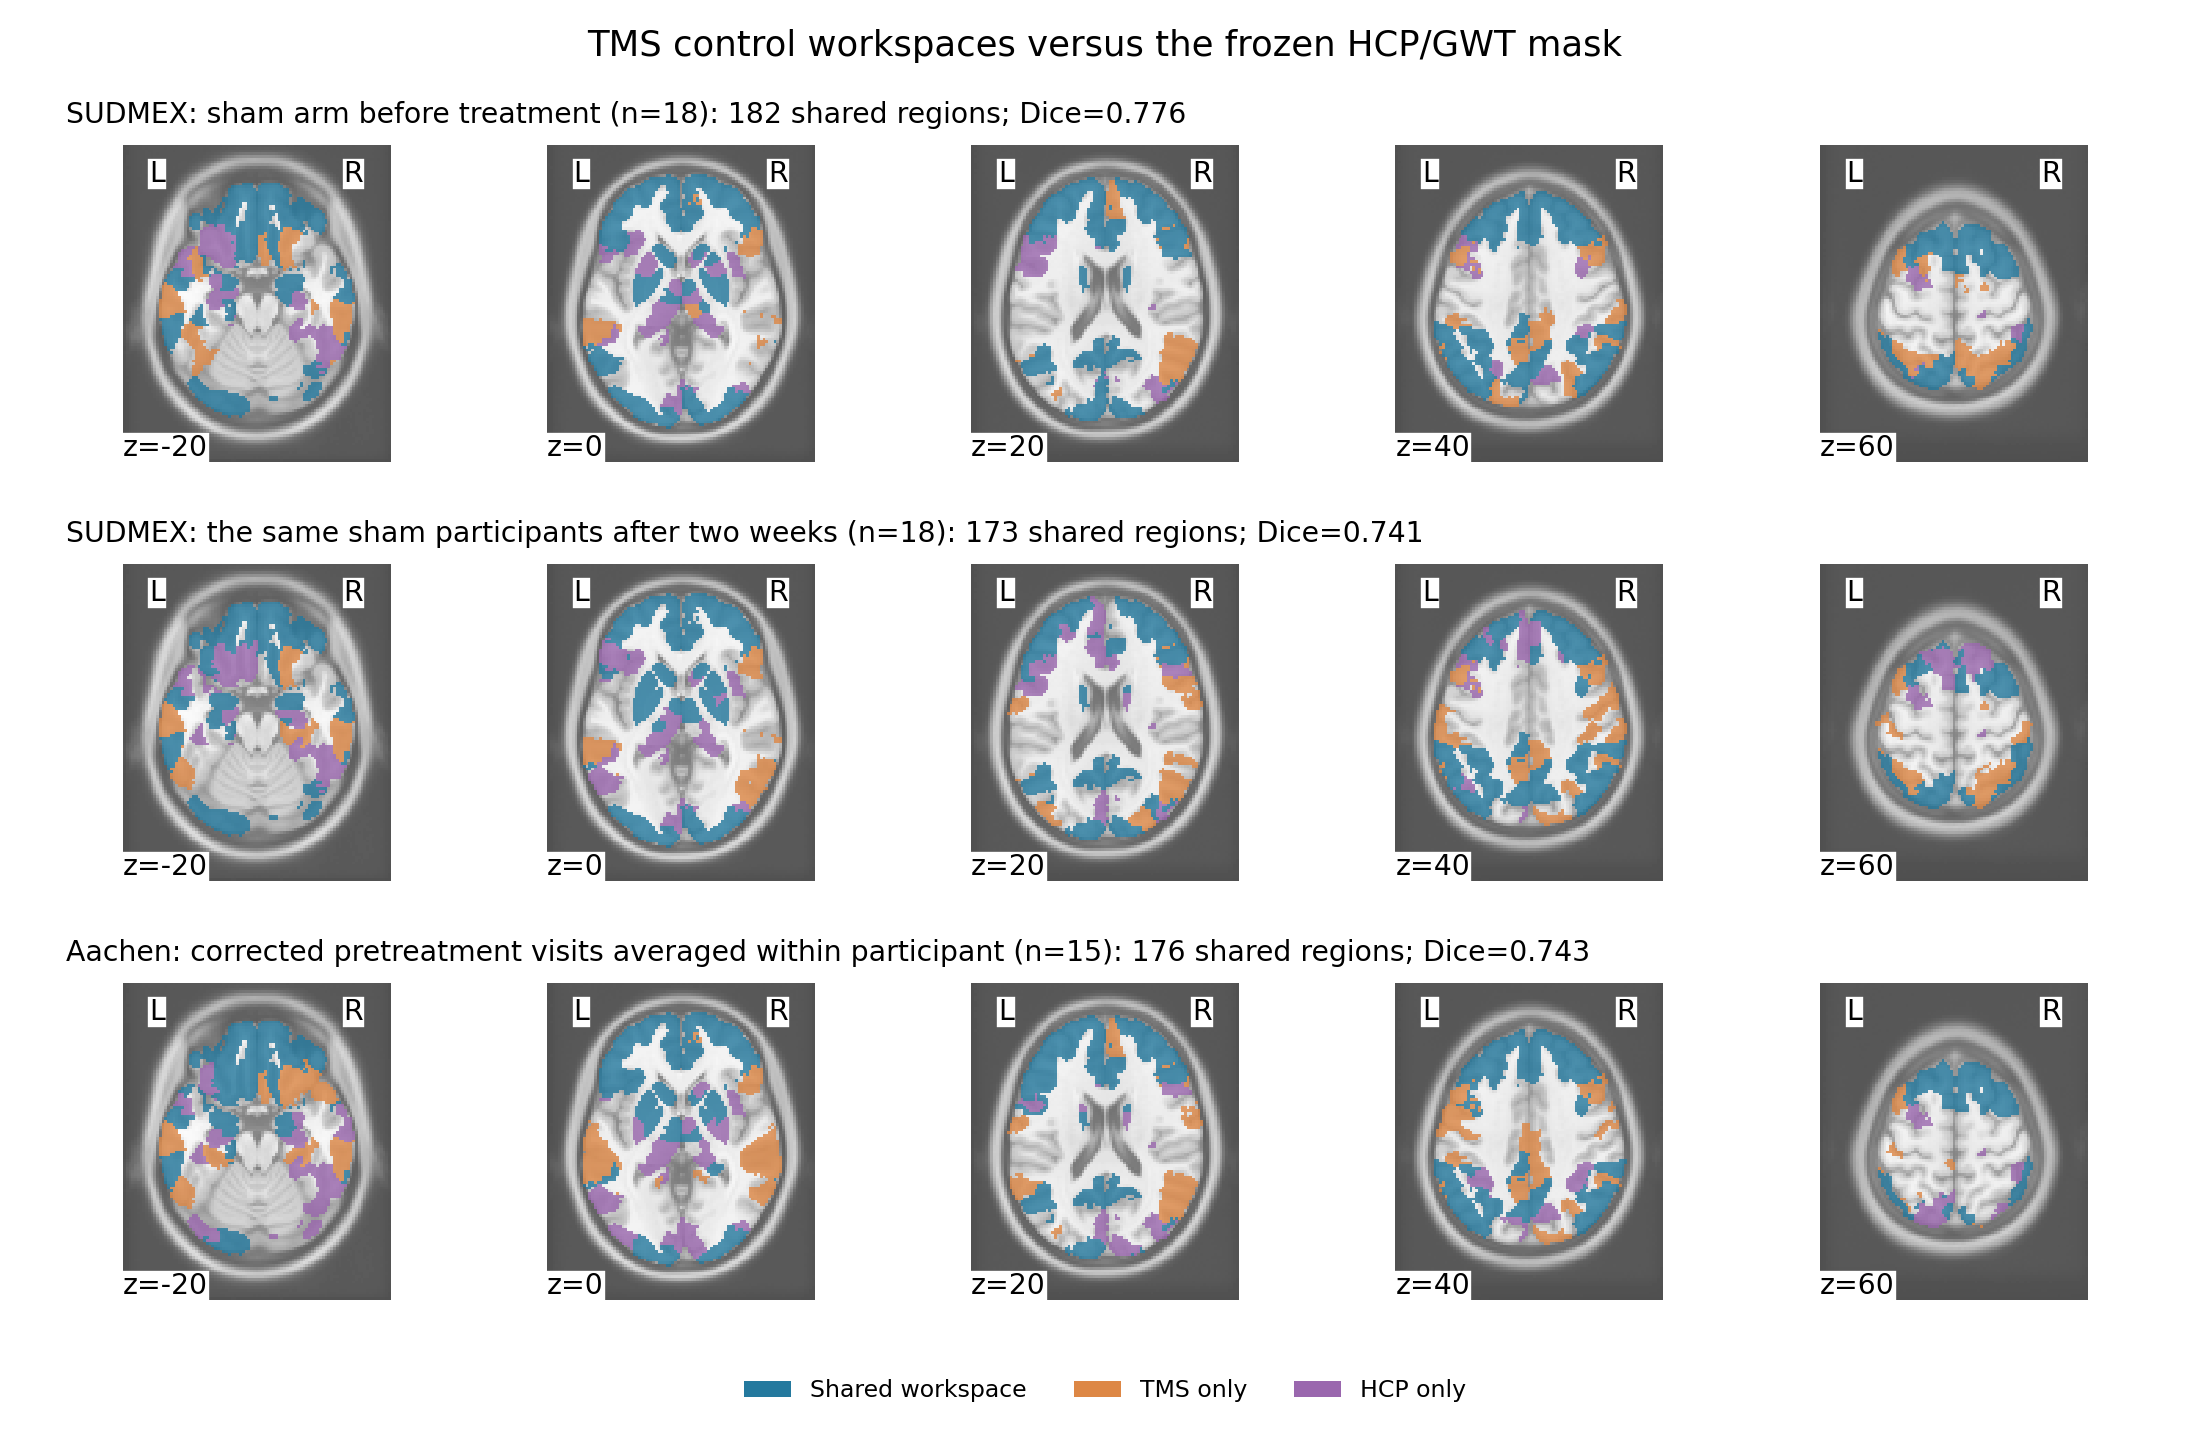

In [11]:
display(Image(filename=str(ROOT/'output/control_workspace_qc/combined_20261125T234309_541220Z/control_workspace_comparison.png'),width=1100))

## Provenance and interpretation
The corrected global Φ estimate and redundancy-participation signal do not survive their relevant families. The study recovers recognizable baseline architecture without establishing the predicted acute workspace reorganization. Full sensitivities and localized model-dependent findings remain in the dashboard and supplement.

In [12]:
display(json.loads((RUN/'analysis_specification.json').read_text()))
print('Manuscript:',ROOT/'manuscript/aachen_brief_report/corrected_20261126')
print('Dashboard:',ROOT/'dashboard/index.html')

{'created_utc': '2026-11-26T11:20:54.284547+00:00',
 'aachen_inputs': 'D:\\projects\\TMS_GWT\\reruns\\aachen_skullstrip_skip_20261125',
 'sudmex_inputs': 'D:\\projects\\TMS_GWT\\pipeline\\results',
 'release_sha256': 'd02401c42be2ea20c9e6de008a30c9665d92e7151467bb0aa4c873a8dfd81895',
 'scope': ['whole_brain', 'within_workspace', 'outside_workspace', 'between'],
 'information_measures': ['synergy',
  'redundancy',
  'synergy_total',
  'phi',
  'phi_r'],
 'role_metrics': ['mean_synergy_pc',
  'mean_redundancy_pc',
  'gateways_total',
  'broadcasters_total',
  'gateways_VIS',
  'gateways_SMN',
  'gateways_DAN',
  'gateways_VAN',
  'gateways_LIM',
  'gateways_FPN',
  'gateways_DMN',
  'gateways_SUB',
  'broadcasters_VIS',
  'broadcasters_SMN',
  'broadcasters_DAN',
  'broadcasters_VAN',
  'broadcasters_LIM',
  'broadcasters_FPN',
  'broadcasters_DMN',
  'broadcasters_SUB'],
 'primary_comparisons': {'aachen': 'Average the two within-visit changes per person; exact joint sign flips, n15.',
 

Manuscript: D:\projects\TMS_GWT\manuscript\aachen_brief_report\corrected_20261126
Dashboard: D:\projects\TMS_GWT\dashboard\index.html
